<a href="https://colab.research.google.com/github/bfzeigler/svd-image-compression/blob/main/notebooks/03%20measuring%20compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3: Measure Compression and Image Quality

Names: Bianca Zeigler


In [1]:
import os
import subprocess
import sys
import importlib

USER = "bfzeigler"
REPO = "svd-image-compression"

if os.path.exists(REPO):
    subprocess.run(
        ["git", "-C", REPO, "pull"],
        check=True
    )
else:
    subprocess.run(
        [
            "git", "clone",
            f"https://github.com/bfzeigler/svd-image-compression.git",
            REPO
        ],
        check=True
    )

src_path = os.path.abspath(f"{REPO}/src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import compress
importlib.reload(compress)

rank_k_approx = compress.rank_k_approx

print("Successfully imported rank_k_approx.")

Successfully imported rank_k_approx.


This code is updating my repository and adding the approximation function.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
m, n = A.shape

T = data.text().astype(float)

print("Camera:", A.shape)
print("Text:", T.shape)

Camera: (512, 512)
Text: (172, 448)


Here, both of the images are being converted into floating point matrices.
The camera image is a square while the text image is rectangular

In [3]:
def storage(m, n, k):
    """Number of values stored in rank-k SVD factors."""
    return k * (m + n + 1)


def compression_ratio(m, n, k):
    """Original value count divided by SVD factor value count."""
    return (m * n) / storage(m, n, k)


print("Original camera values:", m * n)

for k in [1, 10, 50, 100, 255, 256]:
    print(
        f"k={k:3d} "
        f"stored={storage(m, n, k):6d} "
        f"ratio={compression_ratio(m, n, k):.4f}"
    )

Original camera values: 262144
k=  1 stored=  1025 ratio=255.7502
k= 10 stored= 10250 ratio=25.5750
k= 50 stored= 51250 ratio=5.1150
k=100 stored=102500 ratio=2.5575
k=255 stored=261375 ratio=1.0029
k=256 stored=262400 ratio=0.9990


The original camera image stores 262,144 values.

A ratio greater than 1 means the SVD factors used fewer values.
A ratio equal to 1 means that the same number of factors were used.
A ratior less than 1 means the SVD factors used more values.

This calculation counts the SVD factors instead of the full image array.

In [4]:
def rel_error(A, B):
    """Relative Frobenius error when B approximates A."""
    return np.linalg.norm(A - B) / np.linalg.norm(A)


for k in [1, 5, 20, 50, 100]:
    Ak = rank_k_approx(A, k)

    print(
        f"k={k:3d} "
        f"relative error={rel_error(A, Ak):.4f}"
    )

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


The relative error measures how diffrent the approximation value is from teh original value. The relative error should decrease as the value of k increases.

In [5]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)


def predicted_error(s, k):
    """Relative rank-k error from the singular values."""
    return np.sqrt(
        np.sum(s[k:] ** 2) / np.sum(s ** 2)
    )


for k in [1, 5, 20, 50, 100]:
    actual = rel_error(A, rank_k_approx(A, k))
    predicted = predicted_error(s, k)

    print(
        f"k={k:3d} "
        f"actual={actual:.6f} "
        f"predicted={predicted:.6f}"
    )

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


s[k:] contains the discarded singular values. Since python begins counting at 0, the slice begins with the k+1st singluar value

In [6]:
ks = np.arange(1, len(s) + 1)

errors = np.array([
    predicted_error(s, k)
    for k in ks
])

for target in [0.10, 0.05, 0.02, 0.01]:
    k = int(ks[errors <= target][0])
    ratio = compression_ratio(m, n, k)

    print(
        f"Target error={target:.0%}: "
        f"k={k}, ratio={ratio:.2f}"
    )

Target error=10%: k=21, ratio=12.18
Target error=5%: k=73, ratio=3.50
Target error=2%: k=186, ratio=1.38
Target error=1%: k=263, ratio=0.97


This code will find the smallest positive rank that meets each error target. A smaller error target will usually require larger ranks and give less storage savings.

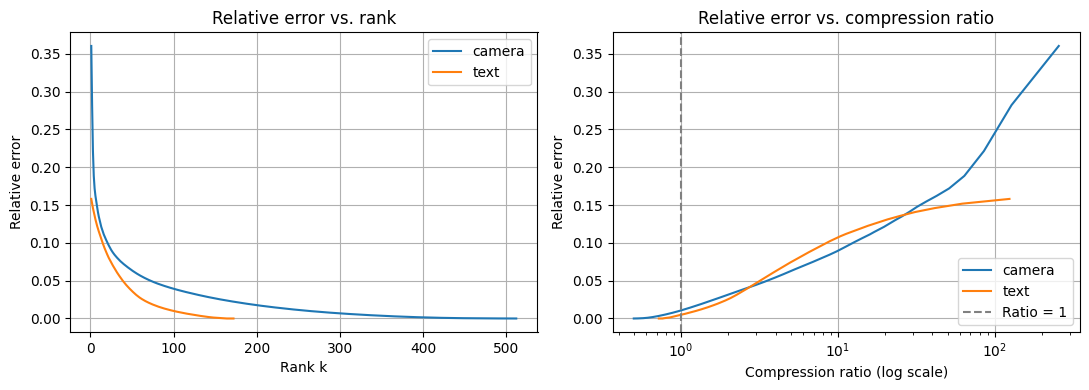

In [7]:
images = {
    "camera": A,
    "text": T
}

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 4)
)

for name, M in images.items():
    m_img, n_img = M.shape

    s_img = np.linalg.svd(M, compute_uv=False)
    ranks = np.arange(1, len(s_img) + 1)

    errs = [
        predicted_error(s_img, k)
        for k in ranks
    ]

    ratios = [
        compression_ratio(m_img, n_img, k)
        for k in ranks
    ]

    ax1.plot(ranks, errs, label=name)
    ax2.semilogx(ratios, errs, label=name)

ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("Rank k")
ax1.set_ylabel("Relative error")

ax2.axvline(
    1, color="gray", linestyle="--",
    label="Ratio = 1"
)
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("Compression ratio (log scale)")
ax2.set_ylabel("Relative error")

for ax in (ax1, ax2):
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()

On these graphs a dashed line marks the ratio of 1, which is where the factors use the same number of values as the original.

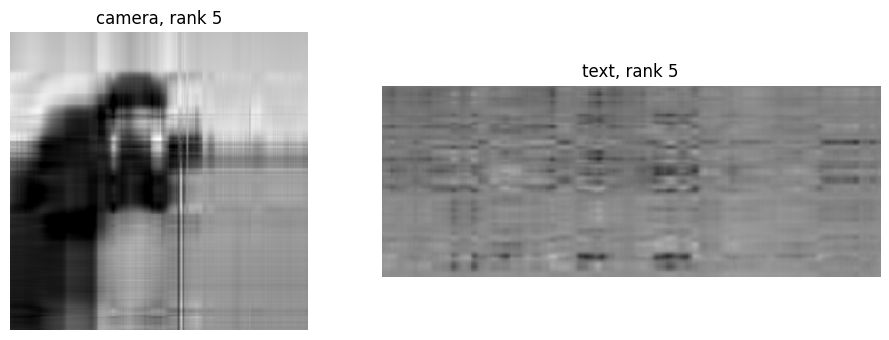

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for ax, (name, M) in zip(axes, images.items()):
    Mk = np.clip(rank_k_approx(M, 5), 0, 255)

    ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}, rank 5")
    ax.axis("off")

plt.tight_layout()
plt.show()

With a rank of 5, neither picture is recognizable.

In [9]:
A20 = rank_k_approx(A, 20)

outside = (A20 < 0) | (A20 > 255)

print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")

print(
    "Error before clipping:",
    round(rel_error(A, A20), 4)
)

print(
    "Error after clipping:",
    round(rel_error(A, np.clip(A20, 0, 255)), 4)
)

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


Clipping will move values that are below 0 to 0 and move values that are above 255 to 255. Clipping can not increase the error when the original pixels are within that range.

In [10]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

Saving IMG_6953.jpeg to IMG_6953 (1).jpeg


My photograph: (600, 800)


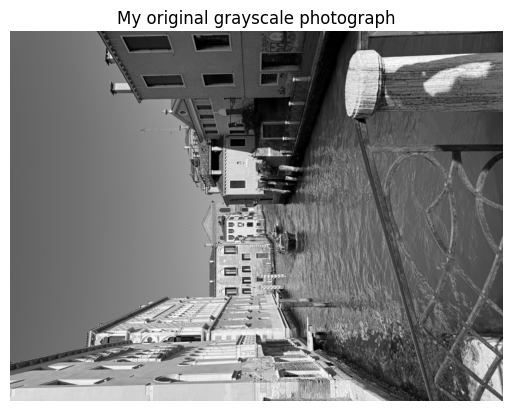

In [11]:
name = list(uploaded)[0]

img = Image.open(name).convert("L")
img.thumbnail((800, 800))

P = np.array(img)
P_float = P.astype(float)

print("My photograph:", P_float.shape)

plt.imshow(P_float, cmap="gray", vmin=0, vmax=255)
plt.title("My original grayscale photograph")
plt.axis("off")
plt.show()

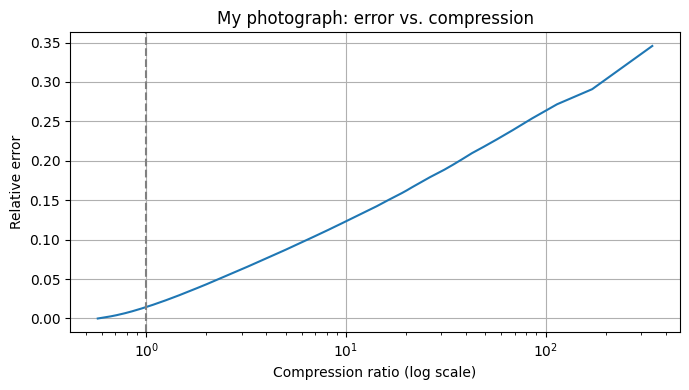

In [12]:
sp = np.linalg.svd(P_float, compute_uv=False)

kp = np.arange(1, len(sp) + 1)

ep = [
    predicted_error(sp, k)
    for k in kp
]

mp, npix = P_float.shape

rp = [
    compression_ratio(mp, npix, k)
    for k in kp
]

plt.figure(figsize=(7, 4))
plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Compression ratio (log scale)")
plt.ylabel("Relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.tight_layout()
plt.show()

A more aggressive compression will usually lead to more error being produced.

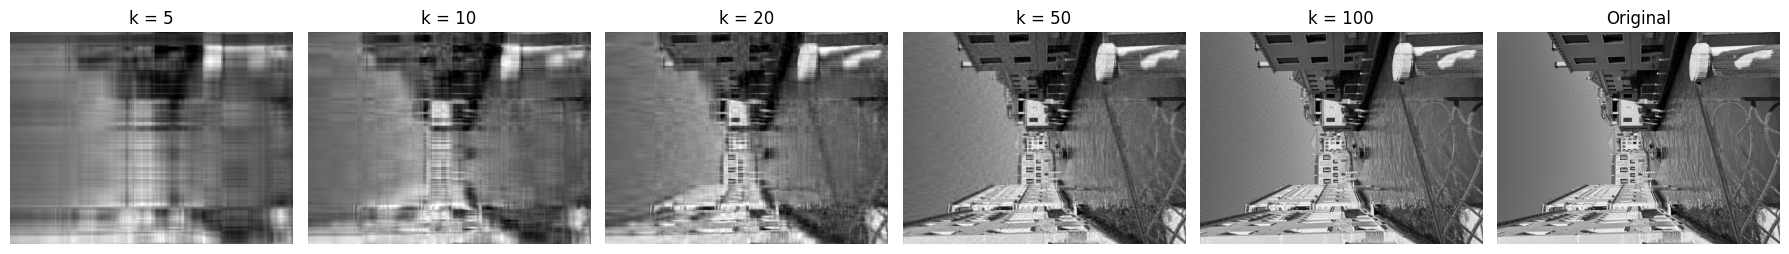

In [13]:
test_ks = [
    k for k in [5, 10, 20, 50, 100]
    if k <= min(P_float.shape)
]

fig, axes = plt.subplots(
    1, len(test_ks) + 1,
    figsize=(3 * (len(test_ks) + 1), 3)
)

for ax, k in zip(axes, test_ks):
    Pk = rank_k_approx(P_float, k)

    ax.imshow(
        np.clip(Pk, 0, 255),
        cmap="gray", vmin=0, vmax=255
    )
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(
    P_float, cmap="gray", vmin=0, vmax=255
)
axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

Chosen rank: 70
Relative error: 8.63%
Count-based compression ratio: 4.89
Original values: 480000
Stored factor values: 98070


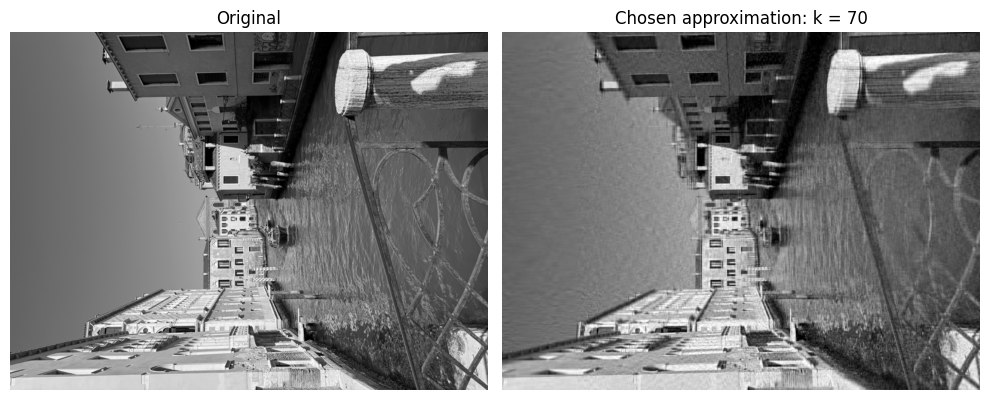

In [14]:
chosen_k = 70

P_chosen = rank_k_approx(P_float, chosen_k)

chosen_error = rel_error(P_float, P_chosen)
chosen_ratio = compression_ratio(mp, npix, chosen_k)

print("Chosen rank:", chosen_k)
print("Relative error:", f"{chosen_error:.2%}")
print("Count-based compression ratio:", f"{chosen_ratio:.2f}")
print("Original values:", mp * npix)
print("Stored factor values:", storage(mp, npix, chosen_k))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    P_float, cmap="gray", vmin=0, vmax=255
)
axes[0].set_title("Original")

axes[1].imshow(
    np.clip(P_chosen, 0, 255),
    cmap="gray", vmin=0, vmax=255
)
axes[1].set_title(f"Chosen approximation: k = {chosen_k}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

I chose a rank of 70 because balances the image quality with the storage savings. When compared to the original, the approximation maintains the key features of the photo while losing some of the finer details. The ratio is greater than 1 meaning the SVD factors store less values than the original image.

## Practice Exercises

##Exercise 1

SVD saves values when:

k(m + n + 1) < mn

Therefore:

k < mn / (m + n + 1)

The largest integer satisfying this strict inequality is:

ceil(mn / (m + n + 1)) - 1

In [15]:
print("U data type:", U.dtype)
print("Bytes per factor value:", U.itemsize)

for name, M in images.items():
    rows, cols = M.shape
    denominator = rows + cols + 1

    # Original pixels use one byte each.
    original_bytes = rows * cols

    # Integer arithmetic preserves the strict inequality.
    max_k_values = (rows * cols - 1) // denominator

    max_k_bytes = (
        (original_bytes - 1)
        // (U.itemsize * denominator)
    )

    print(f"\n{name}")
    print("Largest k saving values:", max_k_values)
    print("First k not saving values:", max_k_values + 1)
    print("Largest k saving bytes:", max_k_bytes)
    print("First k not saving bytes:", max_k_bytes + 1)

U data type: float64
Bytes per factor value: 8

camera
Largest k saving values: 255
First k not saving values: 256
Largest k saving bytes: 31
First k not saving bytes: 32

text
Largest k saving values: 124
First k not saving values: 125
Largest k saving bytes: 15
First k not saving bytes: 16


uint8 pixels use one byte each while float64 entries use eight bytes each. These are idealized array storage compressions that will exclude the file headers.

##Exercise 2

In [16]:
norm_squared = np.linalg.norm(A) ** 2
singular_sum = np.sum(s ** 2)

print("Squared Frobenius norm:", norm_squared)
print("Sum of squared singular values:", singular_sum)
print("Approximately equal?", np.isclose(norm_squared, singular_sum))

Squared Frobenius norm: 5788200983.000001
Sum of squared singular values: 5788200983.0
Approximately equal? True


The squared Frobenius norm of an image is eqaul to teh sum of all the squared singular values.

Eckart Young will give the squared approximation error as the sum of the discarded squared singular values.

To get the relative error you divide those two sums and then take the square root.

##Exercise 3

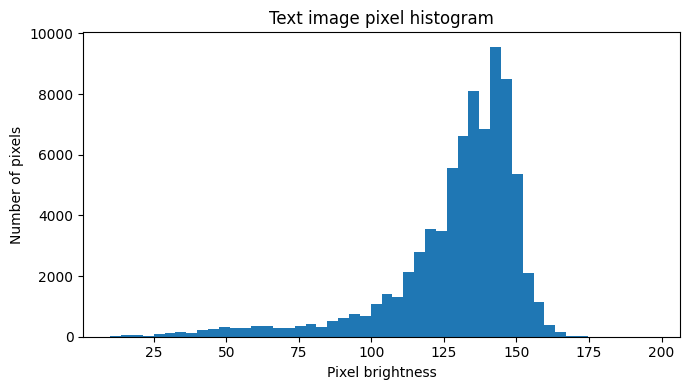

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(T.ravel(), bins=50)
plt.xlabel("Pixel brightness")
plt.ylabel("Number of pixels")
plt.title("Text image pixel histogram")
plt.tight_layout()
plt.show()

The brightness range that contains the most pixels is from about 100-150.

The background can dominate the numerical error even if the letter details become blurred

##Exercise 4

In [18]:
all_images = {
    "camera": A,
    "text": T,
    "my photograph": P_float
}

results = []

for name, M in all_images.items():
    rows, cols = M.shape
    singular_values = np.linalg.svd(M, compute_uv=False)

    ranks = np.arange(1, len(singular_values) + 1)

    image_errors = np.array([
        predicted_error(singular_values, k)
        for k in ranks
    ])

    k10 = int(ranks[image_errors <= 0.10][0])
    ratio10 = compression_ratio(rows, cols, k10)

    results.append((name, k10, ratio10))

    print(
        f"{name}: k={k10}, "
        f"error={predicted_error(singular_values, k10):.2%}, "
        f"ratio={ratio10:.2f}"
    )

winner = max(results, key=lambda result: result[2])

print("\nLargest compression ratio at 10% error:", winner[0])

camera: k=21, error=9.88%, ratio=12.18
text: k=15, error=9.89%, ratio=8.27
my photograph: k=54, error=9.93%, ratio=6.34

Largest compression ratio at 10% error: camera


The camera has the largest compression ratio at a 10% error.

When early terms capture the most of the squared singular value sums then fewer terms are needed. Image dimensions can also have an affect on the storage ratio.

##Exercise 5

Let a be a true pixel value between 0 and 255.

Case 1: x < 0
Clipping changes x to 0.
The original distance is a - x, and the new distance is a.
Since x is negative, the new distance is smaller.

Case 2: 0 <= x <= 255
Clipping leaves x unchanged, so the distance is unchanged.

Case 3: x > 255
Clipping changes x to 255.
The original distance is x - a, and the new distance is 255 - a.
Since x > 255, the new distance is smaller.

From these cases we can determine taht clipping cannot increase the absolute error of a pixel. It also cannot increse the sum of the squared pixel errors or its squre root. This means that the Frobenius error cannot increse either.

##Exercise 6

I would use rank 70 or above to share my image.

Its relative Frobenius error is 8.63% and the count-based
compression ratio is 4.89

I chose this rank because you can depict the photo and see the overall image itself. You do lose some of the finer details but you can still decipher the photo.

In [19]:
files.download("error_vs_ratio.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>